# Phân tích dữ liệu nâng cao: Bank Marketing
**Đề tài:** Phân tích dữ liệu và dự đoán khả năng khách hàng đăng ký tiền gửi có kỳ hạn.

**Mục tiêu**
- Khám phá dữ liệu chiến dịch tiếp thị ngân hàng.
- Tiền xử lý dữ liệu phù hợp cho mô hình học máy.
- So sánh Logistic Regression, Decision Tree và Random Forest.
- Diễn giải kết quả và đề xuất hướng hỗ trợ quyết định.

**Nguồn dữ liệu:** UCI Machine Learning Repository, Bank Marketing (Moro, Rita & Cortez, 2014).  
Trang chính thức: https://archive.ics.uci.edu/dataset/222/bank

**Lưu ý phương pháp:** Loại biến `duration` khỏi mô hình dự đoán trước cuộc gọi vì thời lượng cuộc gọi chỉ được biết sau khi cuộc gọi diễn ra. Các kết quả số sẽ được tạo khi chạy notebook, không điền trước kết quả giả định.


## 1. Cài đặt và import thư viện
Google Colab thường đã có sẵn các thư viện chính. Nếu thiếu, có thể cài đặt ở ô dưới.

In [ ]:
# Nếu cần, bỏ dấu # để cài đặt thư viện
# %pip install pandas numpy matplotlib seaborn scikit-learn

import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Tải và đọc dữ liệu
Tải tệp ZIP từ nguồn UCI chính thức và đọc `bank-full.csv`. Tệp này sử dụng dấu chấm phẩy (`;`) làm dấu phân cách.

In [ ]:

import io
import zipfile
import urllib.request
from pathlib import Path

import pandas as pd

DATA_DIR = Path("bank_marketing_data")
DATA_DIR.mkdir(exist_ok=True)

zip_path = DATA_DIR / "bank-marketing.zip"
data_url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

# Bước 1: Tải dữ liệu nếu chưa có tệp ZIP
if not zip_path.exists() or zip_path.stat().st_size == 0:
    print("Đang tải dữ liệu từ UCI...")
    request = urllib.request.Request(
        data_url,
        headers={"User-Agent": "Mozilla/5.0"}
    )
    with urllib.request.urlopen(request, timeout=60) as response:
        zip_path.write_bytes(response.read())

# Bước 2: Kiểm tra tệp ZIP
if not zipfile.is_zipfile(zip_path):
    zip_path.unlink(missing_ok=True)
    raise ValueError(
        "Tệp tải về không phải ZIP hợp lệ. "
        "Hãy chạy lại ô này để tải lại dữ liệu."
    )

# Bước 3: Tìm bank-full.csv, kể cả trong ZIP lồng nhau
def find_csv_in_zip(zip_bytes, depth=0, max_depth=4):
    if depth > max_depth:
        return None

    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        files = archive.namelist()

        # In danh sách tệp ở lần tìm đầu để tiện kiểm tra
        if depth == 0:
            print("Các tệp trong ZIP ban đầu:")
            for name in files[:30]:
                print(" -", name)

        # Tìm đúng tên tệp, không phụ thuộc chữ hoa/thường
        for name in files:
            if Path(name).name.lower() == "bank-full.csv":
                with archive.open(name) as f:
                    return f.read()

        # Nếu có ZIP bên trong, tiếp tục tìm
        for name in files:
            if name.lower().endswith(".zip"):
                with archive.open(name) as f:
                    nested_bytes = f.read()
                result = find_csv_in_zip(
                    nested_bytes,
                    depth=depth + 1,
                    max_depth=max_depth
                )
                if result is not None:
                    return result

    return None

csv_bytes = find_csv_in_zip(zip_path.read_bytes())

if csv_bytes is None:
    raise FileNotFoundError(
        "Không tìm thấy bank-full.csv trong ZIP hoặc ZIP lồng nhau. "
        "Hãy kiểm tra danh sách tệp được in ở trên."
    )

# Bước 4: Đọc CSV với dấu phân cách ;
df = pd.read_csv(io.BytesIO(csv_bytes), sep=";")

print("\nĐã đọc dữ liệu thành công!")
print("Kích thước dữ liệu:", df.shape)
print("Tên các cột:", df.columns.tolist())
display(df.head())


Đang tải dữ liệu từ UCI...
Các tệp trong ZIP ban đầu:
 - bank.zip
 - bank-additional.zip

Đã đọc dữ liệu thành công!
Kích thước dữ liệu: (45211, 17)
Tên các cột: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Tổng quan dữ liệu
Kiểm tra kích thước, tên cột, kiểu dữ liệu, thống kê mô tả và số lượng giá trị phân biệt.

In [ ]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("\nTên cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.rename("data_type").to_frame())

print("\nThống kê mô tả biến số:")
display(df.describe().T)

print("\nThống kê mô tả toàn bộ biến:")
display(df.describe(include="all").T)

summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=False),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
display(summary)


Số dòng: 45211
Số cột: 17

Tên cột:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Kiểu dữ liệu:


,data_type
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Thống kê mô tả biến số:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0



Thống kê mô tả toàn bộ biến:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


,data_type,unique_values,missing_values,missing_percent
age,int64,77,0,0.0
job,object,12,0,0.0
marital,object,3,0,0.0
education,object,4,0,0.0
default,object,2,0,0.0
balance,int64,7168,0,0.0
housing,object,2,0,0.0
loan,object,2,0,0.0
contact,object,3,0,0.0
day,int64,31,0,0.0


## 4. Kiểm tra chất lượng dữ liệu
Giá trị `unknown` trong một số cột là một nhãn được ghi trong dữ liệu, không phải giá trị thiếu dạng NaN. Ta kiểm tra riêng để mô tả chính xác, không tự động xóa các bản ghi này.

In [ ]:
print("Số dòng trùng lặp hoàn toàn:", df.duplicated().sum())
print("\nGiá trị thiếu NaN theo cột:")
display(df.isna().sum().rename("missing_count").to_frame())

categorical_cols_all = df.select_dtypes(include="object").columns.tolist()
unknown_counts = {}
for col in categorical_cols_all:
    unknown_counts[col] = int((df[col].astype(str).str.lower() == "unknown").sum())

unknown_table = pd.DataFrame.from_dict(
    unknown_counts, orient="index", columns=["unknown_count"]
).sort_values("unknown_count", ascending=False)
display(unknown_table)

print("Phân bố biến mục tiêu y:")
display(df["y"].value_counts(dropna=False).to_frame("count"))
display((df["y"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))


Số dòng trùng lặp hoàn toàn: 0

Giá trị thiếu NaN theo cột:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


,unknown_count
poutcome,36959
contact,13020
education,1857
job,288
marital,0
default,0
loan,0
housing,0
month,0
y,0


Phân bố biến mục tiêu y:


,count
y,
no,39922
yes,5289


,percent
y,
no,88.3
yes,11.7


## 5. Phân tích khám phá dữ liệu (EDA)
Các biểu đồ dưới đây được dùng để tìm hiểu phân bố nhãn mục tiêu, tuổi, số dư tài khoản, nghề nghiệp và tỷ lệ đăng ký theo một số nhóm. Nhận xét trong báo cáo phải dựa trên biểu đồ và kết quả thực tế sau khi chạy.

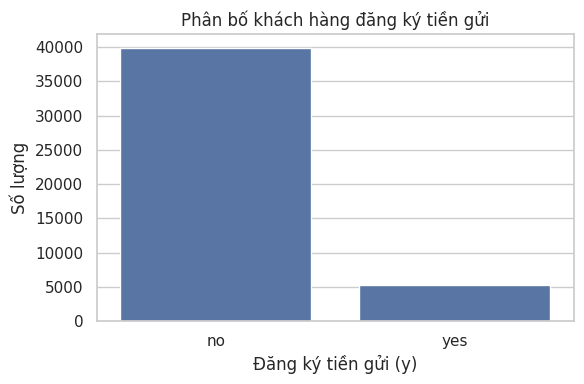

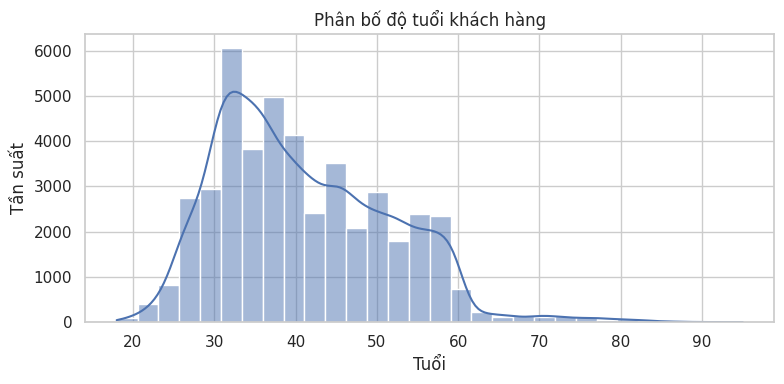

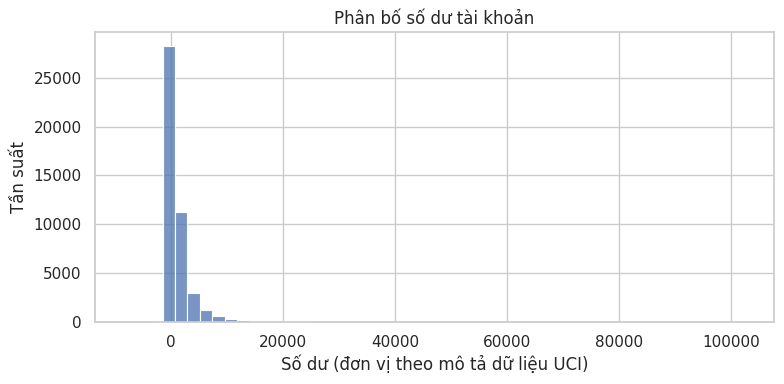

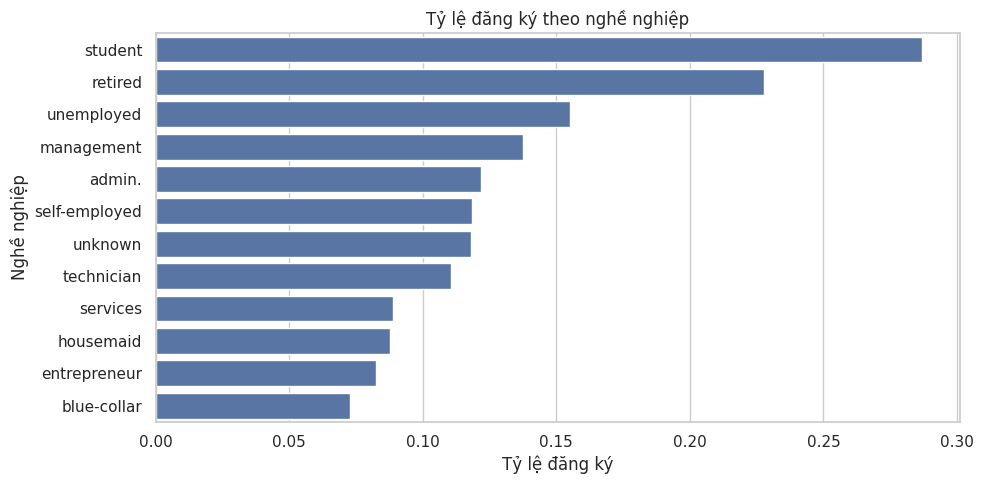

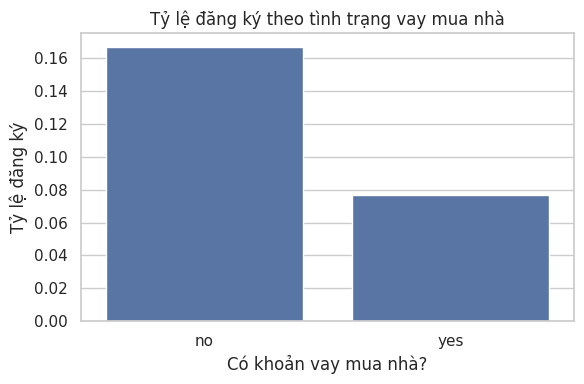

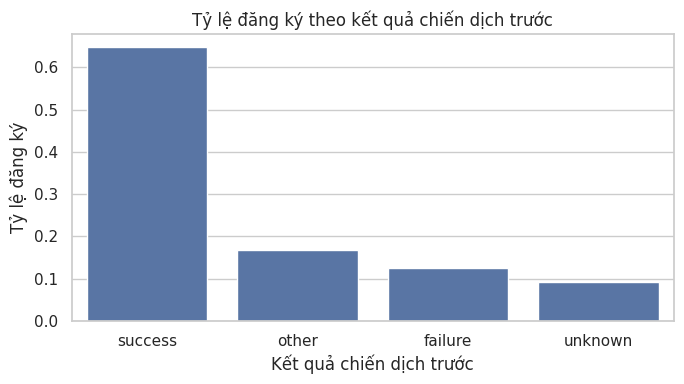

In [ ]:
# 5.1 Phân bố biến mục tiêu
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y", order=df["y"].value_counts().index)
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi (y)")
plt.ylabel("Số lượng")
plt.tight_layout()
plt.show()

# 5.2 Phân bố tuổi
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Phân bố độ tuổi khách hàng")
plt.xlabel("Tuổi")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.show()

# 5.3 Phân bố số dư tài khoản
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="balance", bins=50)
plt.title("Phân bố số dư tài khoản")
plt.xlabel("Số dư (đơn vị theo mô tả dữ liệu UCI)")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.show()

# 5.4 Tỷ lệ đăng ký theo nghề nghiệp
job_rate = (
    df.assign(subscribed=(df["y"] == "yes").astype(int))
      .groupby("job")["subscribed"].mean()
      .sort_values(ascending=False)
)
plt.figure(figsize=(10, 5))
sns.barplot(x=job_rate.values, y=job_rate.index)
plt.title("Tỷ lệ đăng ký theo nghề nghiệp")
plt.xlabel("Tỷ lệ đăng ký")
plt.ylabel("Nghề nghiệp")
plt.tight_layout()
plt.show()

# 5.5 Tỷ lệ đăng ký theo tình trạng vay mua nhà
housing_rate = (
    df.assign(subscribed=(df["y"] == "yes").astype(int))
      .groupby("housing")["subscribed"].mean()
      .sort_values(ascending=False)
)
plt.figure(figsize=(6, 4))
sns.barplot(x=housing_rate.index, y=housing_rate.values)
plt.title("Tỷ lệ đăng ký theo tình trạng vay mua nhà")
plt.xlabel("Có khoản vay mua nhà?")
plt.ylabel("Tỷ lệ đăng ký")
plt.tight_layout()
plt.show()

# 5.6 Tỷ lệ đăng ký theo kết quả chiến dịch trước
poutcome_rate = (
    df.assign(subscribed=(df["y"] == "yes").astype(int))
      .groupby("poutcome")["subscribed"].mean()
      .sort_values(ascending=False)
)
plt.figure(figsize=(7, 4))
sns.barplot(x=poutcome_rate.index, y=poutcome_rate.values)
plt.title("Tỷ lệ đăng ký theo kết quả chiến dịch trước")
plt.xlabel("Kết quả chiến dịch trước")
plt.ylabel("Tỷ lệ đăng ký")
plt.tight_layout()
plt.show()


### 5.7 Bảng tỷ lệ đăng ký theo nhóm
Bảng này giúp đối chiếu số lượng và tỷ lệ đăng ký. Các mối liên hệ quan sát được không tự động chứng minh quan hệ nhân quả.

In [ ]:
def subscription_summary(data, group_col):
    result = (
        data.groupby(group_col, dropna=False)
        .agg(
            customers=("y", "size"),
            subscribed=("y", lambda s: (s == "yes").sum())
        )
    )
    result["subscription_rate_percent"] = (
        result["subscribed"] / result["customers"] * 100
    ).round(2)
    return result.sort_values("subscription_rate_percent", ascending=False)

display(subscription_summary(df, "job"))
display(subscription_summary(df, "education"))
display(subscription_summary(df, "marital"))


,customers,subscribed,subscription_rate_percent
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


,customers,subscribed,subscription_rate_percent
education,,,
tertiary,13301,1996,15.01
unknown,1857,252,13.57
secondary,23202,2450,10.56
primary,6851,591,8.63


,customers,subscribed,subscription_rate_percent
marital,,,
single,12790,1912,14.95
divorced,5207,622,11.95
married,27214,2755,10.12


### 5.8 Trực quan hóa dữ liệu bổ sung

Phần này bổ sung các biểu đồ để xem xét mối liên hệ giữa các biến số, so sánh nhóm khách hàng đăng ký và không đăng ký, đồng thời quan sát tỷ lệ đăng ký theo tháng và số lần liên hệ trong chiến dịch hiện tại.

Lưu ý: các biểu đồ mô tả mối liên hệ trong dữ liệu, không chứng minh quan hệ nhân quả. Cột `duration` có thể hữu ích cho EDA mô tả, nhưng vẫn bị loại khỏi mô hình dự đoán trước cuộc gọi để tránh rò rỉ thông tin.

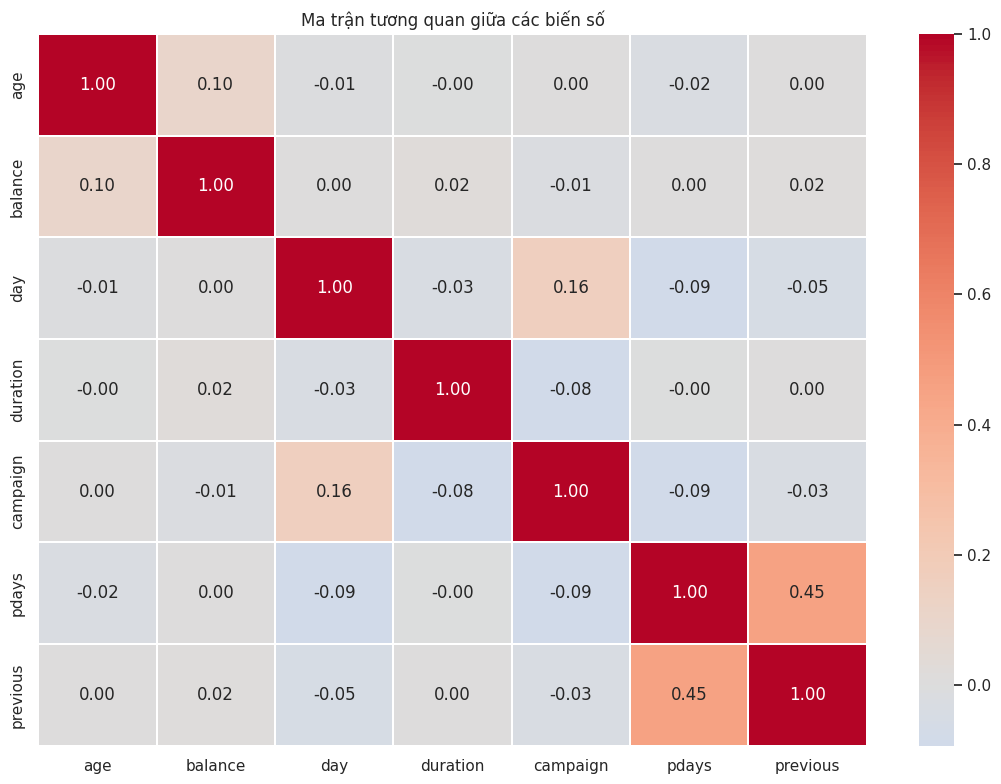

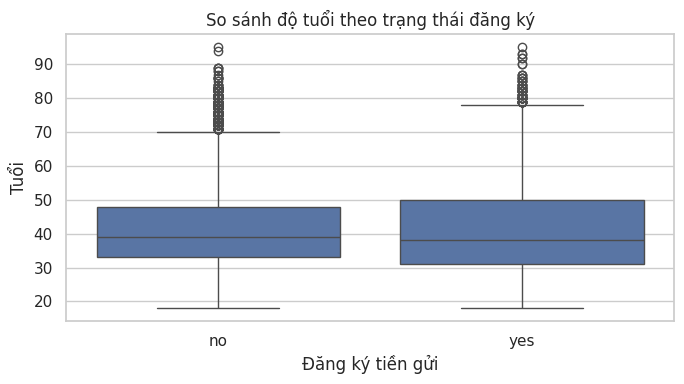

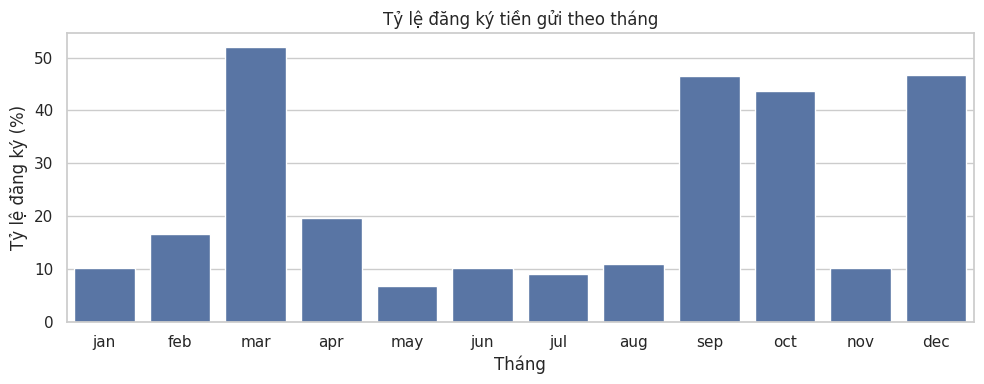

,Số khách hàng,Tỷ lệ đăng ký (%)
month,,
jan,1403,10.12
feb,2649,16.65
mar,477,51.99
apr,2932,19.68
may,13766,6.72
jun,5341,10.22
jul,6895,9.09
aug,6247,11.01
sep,579,46.46


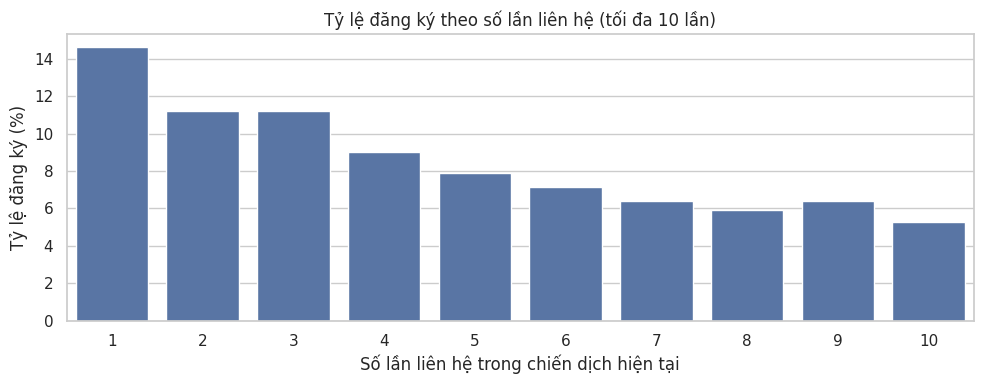

,Số khách hàng,Tỷ lệ đăng ký (%)
campaign,,
1,17544,14.60
2,12505,11.20
3,5521,11.19
4,3522,9.00
5,1764,7.88
6,1291,7.13
7,735,6.39
8,540,5.93
9,327,6.42


In [ ]:
# 5.8.1 Ma trận tương quan giữa các biến số
numeric_cols = df.select_dtypes(include="number").columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=False,
    linewidths=0.3
)
plt.title("Ma trận tương quan giữa các biến số")
plt.tight_layout()
plt.show()

# 5.8.2 So sánh phân bố tuổi giữa hai nhóm mục tiêu
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="y", y="age", order=["no", "yes"])
plt.title("So sánh độ tuổi theo trạng thái đăng ký")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Tuổi")
plt.tight_layout()
plt.show()

# 5.8.3 Tỷ lệ đăng ký theo tháng
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]
monthly_rate = (
    df.assign(subscribed=(df["y"] == "yes").astype(int))
      .groupby("month")["subscribed"]
      .agg(["mean", "count"])
      .reindex(month_order)
      .dropna()
)
monthly_rate["rate_percent"] = monthly_rate["mean"] * 100

plt.figure(figsize=(10, 4))
sns.barplot(
    x=monthly_rate.index,
    y=monthly_rate["rate_percent"],
    order=monthly_rate.index
)
plt.title("Tỷ lệ đăng ký tiền gửi theo tháng")
plt.xlabel("Tháng")
plt.ylabel("Tỷ lệ đăng ký (%)")
plt.tight_layout()
plt.show()

display(monthly_rate[["count", "rate_percent"]].rename(
    columns={"count": "Số khách hàng", "rate_percent": "Tỷ lệ đăng ký (%)"}
).round(2))

# 5.8.4 Tỷ lệ đăng ký theo số lần liên hệ trong chiến dịch hiện tại
# Giới hạn hiển thị đến 10 lần liên hệ để nhóm có tần suất rất thấp
# không làm biểu đồ quá khó đọc; bảng dưới vẫn ghi rõ phạm vi hiển thị.
campaign_view = df[df["campaign"] <= 10].copy()
campaign_rate = (
    campaign_view.assign(subscribed=(campaign_view["y"] == "yes").astype(int))
                 .groupby("campaign")["subscribed"]
                 .agg(["mean", "count"])
)
campaign_rate["rate_percent"] = campaign_rate["mean"] * 100

plt.figure(figsize=(10, 4))
sns.barplot(
    x=campaign_rate.index,
    y=campaign_rate["rate_percent"]
)
plt.title("Tỷ lệ đăng ký theo số lần liên hệ (tối đa 10 lần)")
plt.xlabel("Số lần liên hệ trong chiến dịch hiện tại")
plt.ylabel("Tỷ lệ đăng ký (%)")
plt.tight_layout()
plt.show()

display(campaign_rate[["count", "rate_percent"]].rename(
    columns={"count": "Số khách hàng", "rate_percent": "Tỷ lệ đăng ký (%)"}
).round(2))


## 6. Chuẩn bị dữ liệu cho mô hình
- Mã hóa nhãn `y`: `yes = 1`, `no = 0`.
- Không dùng `duration` vì mục tiêu là dự đoán trước cuộc gọi.
- Chia dữ liệu train/test theo tỷ lệ 80/20, có `stratify` để giữ tỷ lệ nhãn tương đối ổn định.
- Dùng One-Hot Encoding cho biến phân loại và chuẩn hóa biến số cho Logistic Regression.
- Các bước học tham số tiền xử lý được đặt trong Pipeline để tránh rò rỉ dữ liệu từ tập kiểm tra.

In [ ]:
TARGET = "y"
LEAKAGE_COLUMN = "duration"

X = df.drop(columns=[TARGET, LEAKAGE_COLUMN]).copy()
y = (df[TARGET] == "yes").astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Số biến đầu vào:", X.shape[1])
print("Biến số:", numeric_features)
print("Biến phân loại:", categorical_features)
print("Tỷ lệ nhãn mục tiêu:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)


Số biến đầu vào: 15
Biến số: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Biến phân loại: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Tỷ lệ nhãn mục tiêu:


,proportion
y,
0,0.883015
1,0.116985


Kích thước X_train: (36168, 15)
Kích thước X_test: (9043, 15)


## 7. Xây dựng pipeline và mô hình
Ba mô hình được sử dụng để so sánh. `class_weight="balanced"` giúp mô hình cân nhắc sự chênh lệch số lượng giữa các lớp; hiệu quả thực tế vẫn phải được đánh giá trên tập test.

In [ ]:
numeric_transformer_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_transformer_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_logistic = ColumnTransformer(transformers=[
    ("num", numeric_transformer_scaled, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", numeric_transformer_tree, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor_logistic),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED
        ))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=SEED
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=SEED
        ))
    ])
}

print("Đã tạo", len(models), "pipeline mô hình.")


Đã tạo 3 pipeline mô hình.


## 8. Huấn luyện và đánh giá mô hình
Không chỉ dùng Accuracy vì lớp `yes` có thể ít hơn đáng kể so với lớp `no`. Ta so sánh Precision, Recall, F1-score và ROC-AUC; các chỉ số này phản ánh những khía cạnh khác nhau của hiệu quả phân loại.

In [ ]:
results = []
fitted_models = {}

for model_name, pipeline in models.items():
    print(f"Đang huấn luyện: {model_name}")
    pipeline.fit(X_train, y_train)
    fitted_models[model_name] = pipeline

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
display(results_df.round(4))


Đang huấn luyện: Logistic Regression
Đang huấn luyện: Decision Tree
Đang huấn luyện: Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,Random Forest,0.8665,0.4411,0.5274,0.4804,0.8027
1,Decision Tree,0.8286,0.3568,0.5794,0.4416,0.7792
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722


### 8.1 Ma trận nhầm lẫn và báo cáo phân loại
Chọn mô hình có ROC-AUC cao nhất trong lần chạy này để minh họa thêm. Việc chọn mô hình cuối cùng cần xem xét cả Recall, Precision, F1 và chi phí của các loại dự đoán sai.

Mô hình đứng đầu theo ROC-AUC trong lần chạy này: Random Forest

Classification report:
                    precision    recall  f1-score   support

Không đăng ký (no)       0.94      0.91      0.92      7985
     Đăng ký (yes)       0.44      0.53      0.48      1058

          accuracy                           0.87      9043
         macro avg       0.69      0.72      0.70      9043
      weighted avg       0.88      0.87      0.87      9043



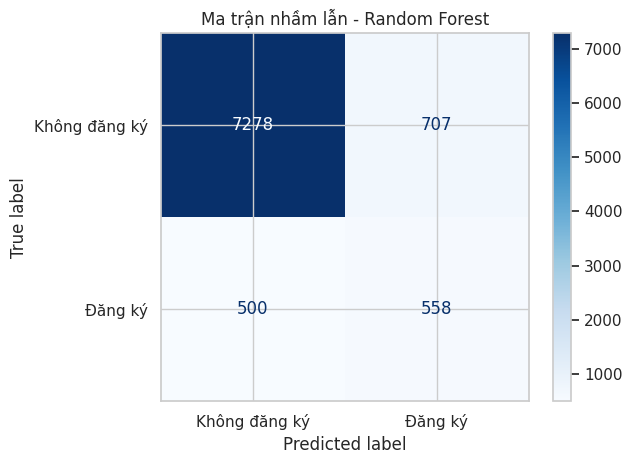

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print("Mô hình đứng đầu theo ROC-AUC trong lần chạy này:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_pred,
    target_names=["Không đăng ký (no)", "Đăng ký (yes)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["Không đăng ký", "Đăng ký"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Ma trận nhầm lẫn - {best_model_name}")
plt.tight_layout()
plt.show()


### 8.2 So sánh đường cong ROC
Đường cong ROC mô tả sự đánh đổi giữa tỷ lệ dương tính thật và tỷ lệ dương tính giả ở các ngưỡng phân loại khác nhau.

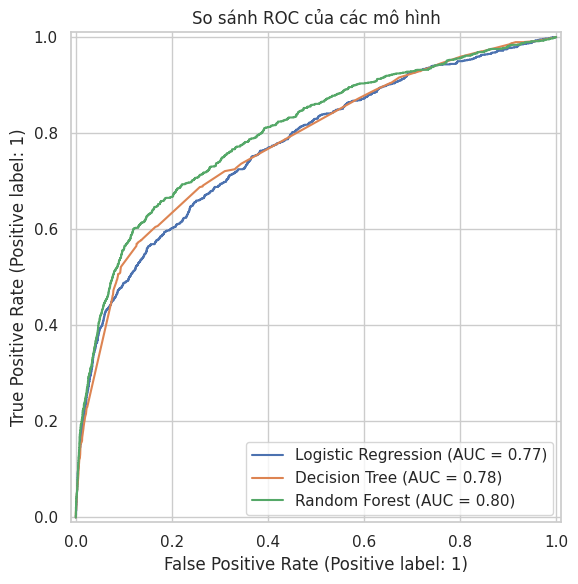

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, pipeline in fitted_models.items():
    RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test, name=model_name, ax=ax
    )
ax.set_title("So sánh ROC của các mô hình")
plt.tight_layout()
plt.show()


## 9. Diễn giải biến quan trọng
Với Random Forest, ta có thể xem các biến sau One-Hot Encoding có mức độ quan trọng tương đối ra sao. Đây là mức độ quan trọng theo mô hình, không phải bằng chứng rằng biến đó gây ra việc đăng ký.

,feature,importance
1,num__balance,0.125034
0,num__age,0.111236
2,num__day,0.099693
48,cat__poutcome_success,0.061310
3,num__campaign,0.055273
4,num__pdays,0.049416
33,cat__contact_unknown,0.042940
31,cat__contact_cellular,0.030201
27,cat__housing_no,0.029701
5,num__previous,0.028216


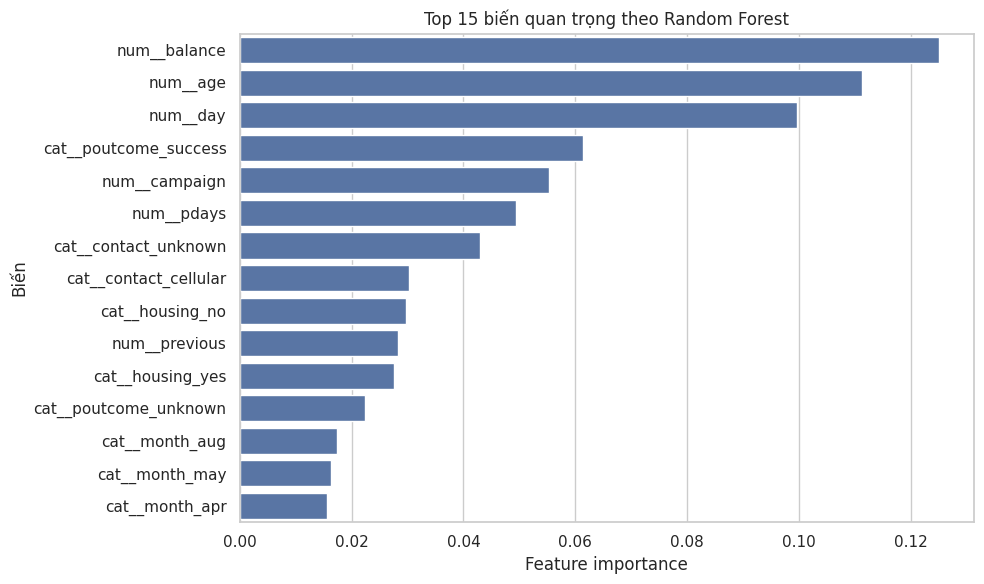

In [ ]:
rf_pipeline = fitted_models["Random Forest"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x="importance", y="feature")
plt.title("Top 15 biến quan trọng theo Random Forest")
plt.xlabel("Feature importance")
plt.ylabel("Biến")
plt.tight_layout()
plt.show()


## 10. Xuất dữ liệu và kết quả
Lưu bản dữ liệu đã đọc và bảng so sánh mô hình để thuận tiện sử dụng khi viết báo cáo. Đây là bản dữ liệu nguồn được đọc vào notebook, chưa phải dữ liệu đã biến đổi thành ma trận đặc trưng.

In [ ]:
output_dir = Path("bank_marketing_outputs")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "bank_marketing_source_copy.csv", index=False)
results_df.to_csv(output_dir / "model_comparison.csv", index=False)
importance_df.to_csv(output_dir / "random_forest_feature_importance.csv", index=False)

print("Đã lưu các tệp vào thư mục:", output_dir.resolve())
print("Các tệp:")
for path in sorted(output_dir.iterdir()):
    print("-", path.name)


Đã lưu các tệp vào thư mục: /content/bank_marketing_outputs
Các tệp:
- bank_marketing_source_copy.csv
- model_comparison.csv
- random_forest_feature_importance.csv


## 11. Khung kết luận dựa trên kết quả thực tế
Sau khi chạy toàn bộ notebook, hãy ghi lại:
1. Những đặc điểm nổi bật của dữ liệu và tỷ lệ hai lớp `yes`/`no`.
2. Các vấn đề chất lượng dữ liệu được phát hiện; phân biệt NaN với nhãn `unknown`.
3. Mô hình có hiệu quả phù hợp nhất theo mục tiêu và lý do chọn.
4. Ý nghĩa của Precision, Recall, F1 và ROC-AUC trong bài toán này.
5. Những biến nổi bật theo mô hình và các giới hạn khi diễn giải.
6. Khuyến nghị tiếp thị có tính thận trọng; mô hình chỉ hỗ trợ ưu tiên tiếp cận, không đảm bảo khách hàng sẽ đăng ký.

**Hạn chế cần nêu:** dữ liệu lịch sử từ một ngân hàng tại Bồ Đào Nha, nên kết quả không mặc nhiên đại diện cho ngân hàng hoặc thị trường Việt Nam. Cần kiểm định lại trên dữ liệu phù hợp trước khi triển khai thực tế.

## Tài liệu tham khảo
Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

UCI Machine Learning Repository. Bank Marketing dataset documentation: https://archive.ics.uci.edu/dataset/222/bank


## 9. Đánh giá nâng cao (đọc từ `backend/metrics.json`)

Các bảng dưới đây do `backend/evaluate.py` sinh tự động, cùng nguồn số liệu với `model.joblib`, báo cáo và endpoint `/metrics`, nên notebook không cần tính lại và không thể lệch số với hai nơi còn lại.

Nội dung gồm kiểm định chéo 5-fold, khoảng tin cậy bootstrap 95% và ngưỡng tối đa hoá lợi nhuận theo giả định C = 25.000 VND mỗi cuộc gọi, V = 400.000 VND mỗi khách đăng ký.


In [1]:
import json
from pathlib import Path

metrics = json.loads(Path("backend/metrics.json").read_text(encoding="utf-8"))
econ = metrics["economics"]
vnd = lambda value: f"{value:,.0f}".replace(",", ".")

print(f"Mô hình: {metrics['config']} | test = {vnd(metrics['test_samples'])} mẫu")
print(f"PR-AUC = {metrics['pr_auc']:.4f} | Brier = {metrics['brier']:.4f} | "
      f"dung lượng = {metrics['model_size_mb']} MB")

cv = metrics["cv"]["scores"]
print(f"\nKiểm định chéo {metrics['cv']['folds']}-fold (trung bình):")
for name in ["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy"]:
    print(f"  {name:<10} {cv[name]:.4f}")

ci = metrics["bootstrap_ci"]
print("\nKhoảng tin cậy bootstrap 95%:")
for name in ["roc_auc", "pr_auc", "recall", "f1"]:
    low, high = ci[name]
    print(f"  {name:<10} [{low:.4f}; {high:.4f}]")

best = metrics["metrics_at_recommended_threshold"]
profit_05 = metrics["tp"] * econ["value_per_deposit_vnd"] - (
    metrics["tp"] + metrics["fp"]
) * econ["cost_per_call_vnd"]

print(f"\nNgưỡng tối đa hoá lợi nhuận: τ* = {best['tau']:.2f}")
print(f"  C = {vnd(econ['cost_per_call_vnd'])} VND/cuộc gọi, "
      f"V = {vnd(econ['value_per_deposit_vnd'])} VND/khách đăng ký")
print(f"  {vnd(best['calls'])} cuộc gọi, Precision {best['precision']:.2%}, "
      f"Recall {best['recall']:.2%}, lợi nhuận {vnd(best['profit'])} VND")
print(f"  Lợi nhuận tại ngưỡng 0.5: {vnd(profit_05)} VND")


Mô hình: rf-150-leaf5 | test = 9.043 mẫu
PR-AUC = 0.4532 | Brier = 0.1159 | dung lượng = 12.3 MB

Kiểm định chéo 5-fold (trung bình):
  roc_auc    0.7975
  pr_auc     0.4432
  recall     0.5243
  precision  0.4337
  f1         0.4747
  accuracy   0.8643

Khoảng tin cậy bootstrap 95%:
  roc_auc    [0.7871; 0.8181]
  pr_auc     [0.4221; 0.4865]
  recall     [0.4981; 0.5564]
  f1         [0.4540; 0.5048]

Ngưỡng tối đa hoá lợi nhuận: τ* = 0.25
  C = 25.000 VND/cuộc gọi, V = 400.000 VND/khách đăng ký
  4.057 cuộc gọi, Precision 21.20%, Recall 81.29%, lợi nhuận 242.575.000 VND
  Lợi nhuận tại ngưỡng 0.5: 191.575.000 VND
